nota_exame - horas_estudo

#Importando bibliotecas

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import statsmodels.api as sm

In [ ]:
df = pd.read_csv ('/content/drive/MyDrive/!dados/Analíse-Preditiva-Exercício/Base_Notas_V1.csv', index_col='id')
df.head()

,horas_estudo,nota_exame
id,,
0,5.993428,76.119754
1,4.723471,60.929961
2,6.295377,81.731317
3,8.046060,82.699637
4,4.531693,70.662399


In [ ]:
df.isna().sum()

,0
horas_estudo,0
nota_exame,0
nova_nota,0


In [ ]:
df.describe().round(2)

,horas_estudo,nota_exame
count,30.00,30.00
mean,4.62,71.81
std,1.80,8.88
min,1.17,54.48
25%,3.82,66.41
50%,4.53,71.40
75%,5.72,78.10
max,8.16,89.47


In [ ]:
df['horas_estudo'] = df['horas_estudo'].astype(str).str[:2]
df['nota_exame'] = df['nota_exame'].astype(str).str[:2]

In [ ]:
df['nota_exame'] = df['nota_exame'].str.replace(',','.')
df['nota_exame'] = df['nota_exame'].astype('float')

In [ ]:
df['horas_estudo'] = df['horas_estudo'].str.replace(',','.')
df['horas_estudo'] = df['horas_estudo'].astype('float')

In [ ]:
df.corr()

,horas_estudo,nota_exame
horas_estudo,1.000000,0.721178
nota_exame,0.721178,1.000000


<Axes: xlabel='horas_estudo', ylabel='nota_exame'>

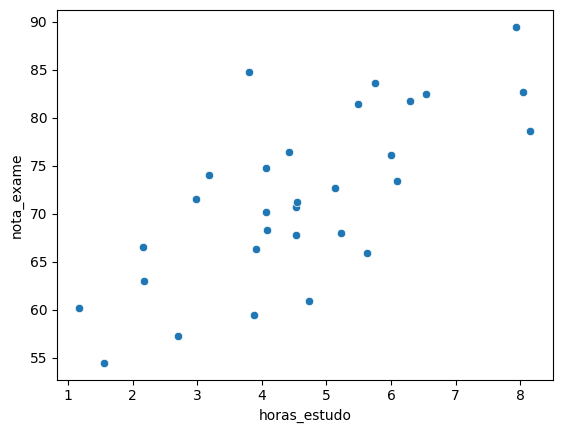

In [ ]:
sns.scatterplot(df, x='horas_estudo', y='nota_exame')

<Axes: >

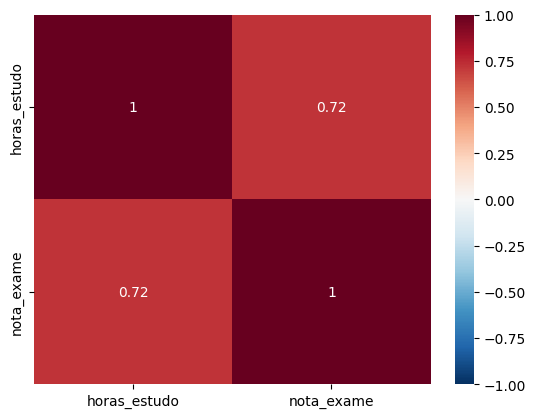

In [ ]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    #cmap= 'RdBu',
    #cmap= 'viridis',
    cmap= 'RdBu_r',
    annot=True
    )

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   horas_estudo  30 non-null     object
 1   nota_exame    30 non-null     object
dtypes: object(2)
memory usage: 720.0+ bytes


In [ ]:
y = df['horas_estudo']

df['intercepto'] = 1
x = df[['nota_exame','intercepto']]

In [ ]:
modelo = sm.OLS(y,x)

In [ ]:
resultado = modelo.fit()

In [ ]:
print(resultado.summary())
#Porcentagem = 52%
#nota_exame = 0.15
#intercepto = -5.88

                            OLS Regression Results                            
Dep. Variable:           horas_estudo   R-squared:                       0.520
Model:                            OLS   Adj. R-squared:                  0.503
Method:                 Least Squares   F-statistic:                     30.35
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           6.92e-06
Time:                        19:33:45   Log-Likelihood:                -48.681
No. Observations:                  30   AIC:                             101.4
Df Residuals:                      28   BIC:                             104.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
nota_exame     0.1462      0.027      5.509      0.0

In [ ]:
df['nova_nota'] = df['nota_exame'] * 0.15 + -5.88
display(df[['nota_exame','nova_nota']])

,nota_exame,nova_nota
id,,
0,76.0,5.52
1,60.0,3.12
2,81.0,6.27
3,82.0,6.42
4,70.0,4.62
5,67.0,4.17
6,78.0,5.82
7,82.0,6.42
8,70.0,4.62


In [ ]:
df.query("nova_nota > 7")

,horas_estudo,nota_exame,nova_nota
id,,,
20,7.0,89.0,7.47
